In [48]:
import pandas as pd
import os
from sqlalchemy import create_engine

In [49]:
data = pd.read_excel("EduPro Online Platform.xlsx", sheet_name=None)

users = data["Users"]
teachers = data["Teachers"]
courses = data["Courses"]
transactions = data["Transactions"]

print(users.shape, teachers.shape, courses.shape, transactions.shape)

(3000, 5) (60, 7) (60, 8) (10000, 7)


In [50]:
transactions["TransactionDate"] = pd.to_datetime(transactions["TransactionDate"])
print(transactions.dtypes)

TransactionID              object
UserID                     object
CourseID                   object
TransactionDate    datetime64[ns]
Amount                    float64
PaymentMethod              object
TeacherID                  object
dtype: object


In [51]:
for name, df in [("users", users), ("teachers", teachers), ("courses", courses), ("transactions", transactions)]:
    print(name, "| missing:", df.isna().sum().sum(), "| duplicates:", df.duplicated().sum())

users | missing: 0 | duplicates: 0
teachers | missing: 0 | duplicates: 0
courses | missing: 0 | duplicates: 0
transactions | missing: 0 | duplicates: 0


In [52]:
t = teachers.rename(columns={"Age": "TeacherAge", "Gender": "TeacherGender"})
u = users.rename(columns={"Age": "UserAge", "Gender": "UserGender"})

df = (transactions
      .merge(courses, on="CourseID", how="left")
      .merge(t, on="TeacherID", how="left")
      .merge(u[["UserID", "UserAge", "UserGender"]], on="UserID", how="left"))

print(df.shape)
df.head()

(10000, 22)


,TransactionID,UserID,CourseID,TransactionDate,Amount,PaymentMethod,TeacherID,CourseName,CourseCategory,CourseType,...,CourseDuration,CourseRating,TeacherName,TeacherAge,TeacherGender,Expertise,YearsOfExperience,TeacherRating,UserAge,UserGender
0,TT00001,U00003,CR00016,2025-10-25,0.0,PayPal,TC00040,Digital Marketing,Marketing,Free,...,42.68,4.72,Kimberly Miller,49,Male,Cybersecurity,24,4.58,33,Female
1,TT00002,U00003,CR00037,2025-01-13,0.0,PayPal,TC00040,Scrum Essentials,Project Management,Free,...,33.93,3.45,Kimberly Miller,49,Male,Cybersecurity,24,4.58,33,Female
2,TT00003,U00003,CR00019,2025-03-28,0.0,Bank Transfer,TC00040,Content Marketing,Marketing,Free,...,18.00,2.98,Kimberly Miller,49,Male,Cybersecurity,24,4.58,33,Female
3,TT00004,U00004,CR00048,2025-06-02,0.0,Bank Transfer,TC00040,AI Ethics,Artificial Intelligence,Free,...,42.70,3.64,Kimberly Miller,49,Male,Cybersecurity,24,4.58,23,Female
4,TT00005,U00004,CR00060,2025-08-10,0.0,PayPal,TC00042,Content Creation,Digital Marketing,Free,...,8.95,2.14,Yolanda Levine,49,Female,Machine Learning,21,4.97,23,Female


In [53]:
df["Month"] = df["TransactionDate"].dt.to_period("M")
df["MonthNum"] = df["TransactionDate"].dt.month
df["Quarter"] = df["TransactionDate"].dt.quarter

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

                         enrollments    revenue
CourseCategory                                 
Artificial Intelligence          829  202750.67
Business                         833  181527.58
Project Management               829  169103.21
Programming                      806   77453.92
Data Science                     916   77052.32
Cybersecurity                    819   59139.00
Digital Marketing                808   56261.32
Design                           827   43113.72
Finance                          864   28106.20
Web Development                  844   16682.15
Machine Learning                 819     133.38
Marketing                        806       0.00


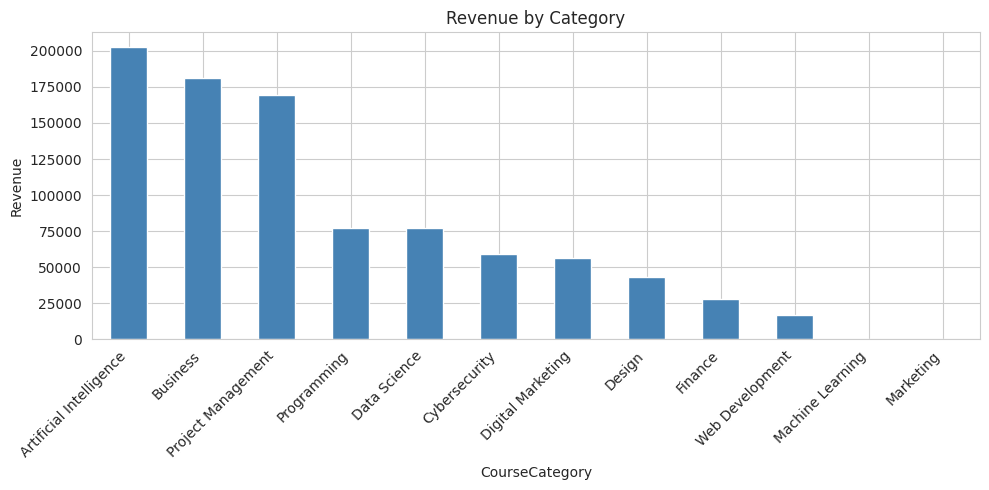

In [55]:
cat = df.groupby("CourseCategory").agg(
    enrollments=("TransactionID", "count"),
    revenue=("Amount", "sum")
).sort_values("revenue", ascending=False)

print(cat)

cat["revenue"].plot(kind="bar", color="steelblue")
plt.title("Revenue by Category")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

            enrollments    revenue
CourseType                        
Free               6403       0.00
Paid               3597  911323.47


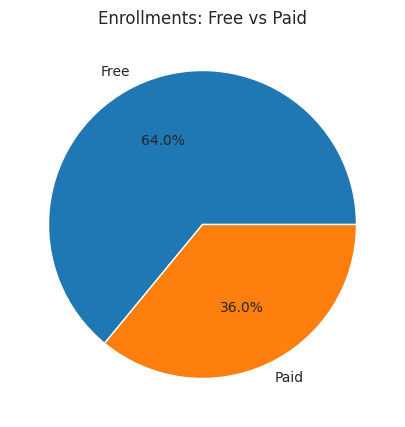

In [56]:
ft = df.groupby("CourseType").agg(
    enrollments=("TransactionID", "count"),
    revenue=("Amount", "sum")
)
print(ft)

ft["enrollments"].plot(kind="pie", autopct="%1.1f%%", ylabel="")
plt.title("Enrollments: Free vs Paid")
plt.show()

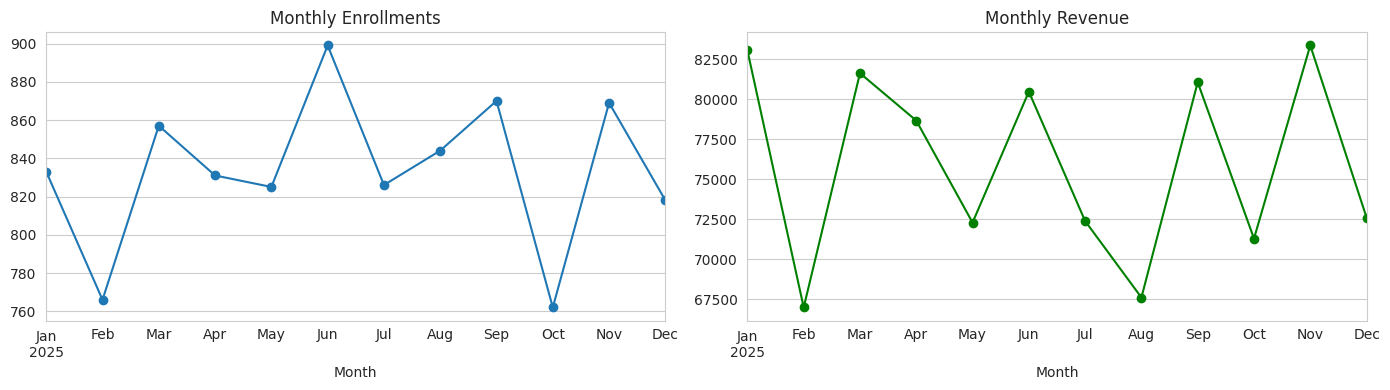

In [57]:
monthly = df.groupby("Month").agg(
    enrollments=("TransactionID", "count"),
    revenue=("Amount", "sum")
)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
monthly["enrollments"].plot(ax=ax[0], marker="o", title="Monthly Enrollments")
monthly["revenue"].plot(ax=ax[1], marker="o", color="green", title="Monthly Revenue")
plt.tight_layout()
plt.show()

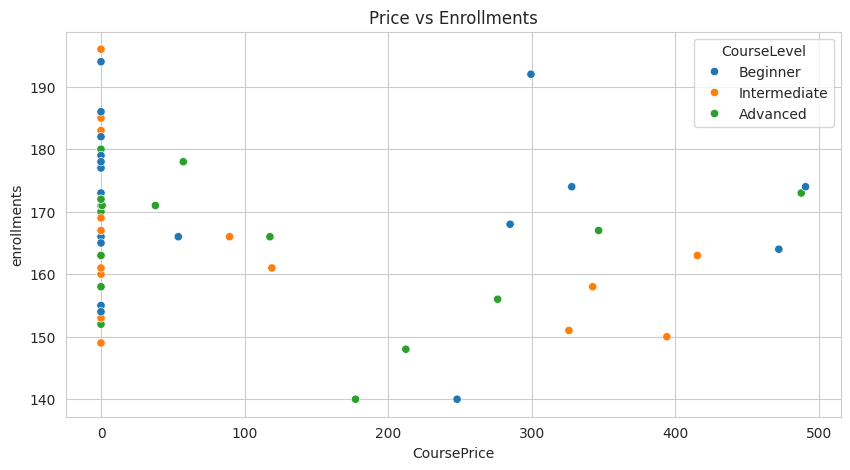

              CoursePrice  CourseRating  enrollments   revenue
CoursePrice      1.000000     -0.031973    -0.163356  0.996722
CourseRating    -0.031973      1.000000     0.294010 -0.018298
enrollments     -0.163356      0.294010     1.000000 -0.116611
revenue          0.996722     -0.018298    -0.116611  1.000000


In [58]:
course_summary = df.groupby(["CourseID", "CourseName", "CoursePrice", "CourseRating", "CourseLevel"]).agg(
    enrollments=("TransactionID", "count"),
    revenue=("Amount", "sum")
).reset_index()

sns.scatterplot(data=course_summary, x="CoursePrice", y="enrollments", hue="CourseLevel")
plt.title("Price vs Enrollments")
plt.show()

print(course_summary[["CoursePrice", "CourseRating", "enrollments", "revenue"]].corr())

In [59]:
print("TOP 10")
print(course_summary.sort_values("revenue", ascending=False).head(10)[["CourseName", "CoursePrice", "enrollments", "revenue"]])

print("\nBOTTOM 10")
print(course_summary.sort_values("revenue").head(10)[["CourseName", "CoursePrice", "enrollments", "revenue"]])

TOP 10
                CourseName  CoursePrice  enrollments   revenue
49         Computer Vision       490.90          174  85416.60
11       Business Strategy       487.92          173  84410.16
0            Python Basics       472.28          164  77453.92
48           Deep Learning       415.51          163  67728.13
33         Data Encryption       394.26          150  59139.00
38        Project Planning       346.71          167  57900.57
24    Statistical Analysis       299.57          192  57517.44
39  Leadership in Projects       327.99          174  57070.26
37         Risk Management       342.61          158  54132.38
10    Entrepreneurship 101       326.02          151  49229.02

BOTTOM 10
                 CourseName  CoursePrice  enrollments  revenue
1          Java Programming          0.0          149      0.0
2         C++ for Beginners          0.0          173      0.0
3           Advanced Python          0.0          154      0.0
4    Full Stack Development          

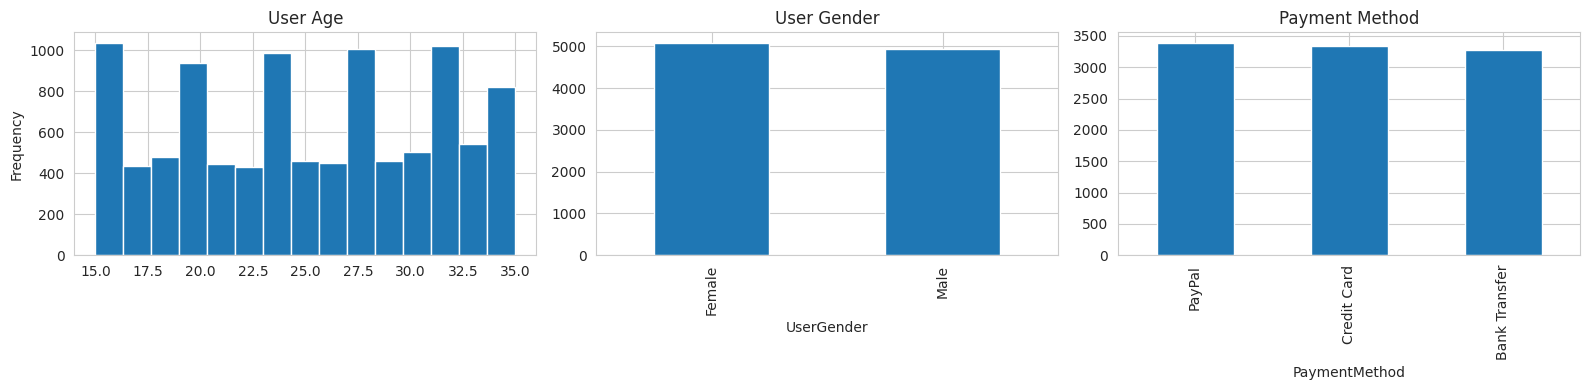

In [60]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df["UserAge"].plot(kind="hist", bins=15, ax=ax[0], title="User Age")
df["UserGender"].value_counts().plot(kind="bar", ax=ax[1], title="User Gender")
df["PaymentMethod"].value_counts().plot(kind="bar", ax=ax[2], title="Payment Method")
plt.tight_layout()
plt.show()

In [61]:
# 1. Course x Month table
full = pd.MultiIndex.from_product(
    [courses["CourseID"], range(1, 13)], names=["CourseID", "MonthNum"]
).to_frame(index=False)

agg = df.groupby(["CourseID", "MonthNum"]).agg(enrollments=("TransactionID", "count")).reset_index()
panel = full.merge(agg, on=["CourseID", "MonthNum"], how="left")
panel["enrollments"] = panel["enrollments"].fillna(0).astype(int)

# 2. Course aur teacher info (sirf ek baar)
teacher_info = df.groupby("CourseID").agg(
    AvgTeacherRating=("TeacherRating", "mean"),
    AvgTeacherExp=("YearsOfExperience", "mean")
).reset_index()

panel = (panel
         .merge(courses, on="CourseID", how="left")
         .merge(teacher_info, on="CourseID", how="left"))

panel["IsPaid"] = (panel["CourseType"] == "Paid").astype(int)
panel["Revenue"] = panel["enrollments"] * panel["CoursePrice"]
panel["Quarter"] = (panel["MonthNum"] - 1) // 3 + 1

# 3. Lag features
panel = panel.sort_values(["CourseID", "MonthNum"]).reset_index(drop=True)
g = panel.groupby("CourseID")["enrollments"]
panel["lag1"] = g.shift(1)
panel["roll3"] = g.transform(lambda s: s.shift(1).rolling(3).mean())
panel = panel.dropna().reset_index(drop=True)

# 4. Encoding
model_df = pd.get_dummies(panel, columns=["CourseCategory", "CourseLevel"], drop_first=True)
drop_cols = ["CourseID", "CourseName", "CourseType", "enrollments", "Revenue"]
features = [c for c in model_df.columns if c not in drop_cols]

# 5. Time split
train = model_df[model_df["MonthNum"] <= 9]
test = model_df[model_df["MonthNum"] >= 10]
X_train, y_train = train[features].astype(float), train["enrollments"]
X_test, y_test = test[features].astype(float), test["enrollments"]

print(len(features), "features")
print(X_train.shape, X_test.shape)

23 features
(360, 23) (180, 23)


In [62]:
results = []
evaluate("Baseline (3-month avg)", y_test, test["roll3"])

In [64]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

results = []

def evaluate(name, y_true, y_pred):
    results.append({
        "Model": name,
        "MAE": round(mean_absolute_error(y_true, y_pred), 2),
        "RMSE": round(np.sqrt(mean_squared_error(y_true, y_pred)), 2),
        "R2": round(r2_score(y_true, y_pred), 3)
    })

evaluate("Baseline (3-month avg)", y_test, test["roll3"])

In [66]:
rf = RandomForestRegressor(n_estimators=300, max_depth=5, random_state=42)
rf.fit(X_train, y_train)
evaluate("Random Forest", y_test, rf.predict(X_test))

In [67]:
best = rf

pred_df = test[["CourseID", "MonthNum", "CoursePrice", "enrollments"]].copy()
pred_df["PredEnrollments"] = best.predict(X_test).clip(min=0)
pred_df["ActualRevenue"] = pred_df["enrollments"] * pred_df["CoursePrice"]
pred_df["PredRevenue"] = pred_df["PredEnrollments"] * pred_df["CoursePrice"]

pred_df = pred_df.merge(courses[["CourseID", "CourseName", "CourseCategory"]], on="CourseID")

print(pred_df[["ActualRevenue", "PredRevenue"]].sum().round(0))

ActualRevenue    227239.0
PredRevenue      228918.0
dtype: float64


In [71]:
cat_rev = pred_df.groupby("CourseCategory")[["ActualRevenue", "PredRevenue"]].sum().round(0)
cat_rev["Error%"] = ((cat_rev["PredRevenue"] - cat_rev["ActualRevenue"]) / cat_rev["ActualRevenue"].replace(0, np.nan) * 100).round(1)
cat_rev = cat_rev.sort_values("ActualRevenue", ascending=False)
print(cat_rev)

                         ActualRevenue  PredRevenue  Error%
CourseCategory                                             
Artificial Intelligence        52438.0      48688.0    -7.2
Business                       46279.0      43248.0    -6.5
Project Management             44356.0      41137.0    -7.3
Programming                    17947.0      20168.0    12.4
Data Science                   17578.0      19987.0    13.7
Cybersecurity                  16165.0      15537.0    -3.9
Digital Marketing              10910.0      17037.0    56.2
Design                         10778.0      11398.0     5.8
Finance                         6536.0       7500.0    14.7
Web Development                 4228.0       4182.0    -1.1
Machine Learning                  23.0         36.0    56.5
Marketing                          0.0          0.0     NaN


In [72]:
monthly_enr = (df.groupby(["CourseID", "MonthNum"]).size().unstack(fill_value=0)
                 .reindex(columns=range(1, 13), fill_value=0)
                 .reindex(courses["CourseID"], fill_value=0))

nxt = pd.DataFrame({
    "CourseID": monthly_enr.index,
    "lag1": monthly_enr[12].values,
    "roll3": monthly_enr[[10, 11, 12]].mean(axis=1).values,
    "MonthNum": 1,
    "Quarter": 1
})

static = panel.drop_duplicates("CourseID")[["CourseID", "CourseCategory", "CourseLevel", "CoursePrice",
                                            "CourseDuration", "CourseRating", "AvgTeacherRating",
                                            "AvgTeacherExp", "IsPaid"]]
nxt = nxt.merge(static, on="CourseID")

nx = pd.get_dummies(nxt, columns=["CourseCategory", "CourseLevel"], drop_first=True)
for c in features:
    if c not in nx:
        nx[c] = 0

nxt["PredEnrollments"] = best.predict(nx[features].astype(float)).clip(min=0)
nxt["PredRevenue"] = nxt["PredEnrollments"] * nxt["CoursePrice"]

print("Jan total predicted enrollments:", round(nxt["PredEnrollments"].sum()))
print("Jan total predicted revenue    :", round(nxt["PredRevenue"].sum()))

Jan total predicted enrollments: 841
Jan total predicted revenue    : 76138


In [73]:
from google.colab import files

pred_df.to_csv("predictions_oct_dec.csv", index=False)
cat_rev.reset_index().to_csv("category_revenue.csv", index=False)
nxt[["CourseID", "CoursePrice", "PredEnrollments", "PredRevenue"]].merge(
    courses[["CourseID", "CourseName", "CourseCategory"]], on="CourseID"
).to_csv("jan_forecast.csv", index=False)
df.to_csv("master_data.csv", index=False)

for f in ["predictions_oct_dec.csv", "category_revenue.csv", "jan_forecast.csv", "master_data.csv"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>